####Downloading and Extracting dataset

In [1]:
!wget https://files.grouplens.org/datasets/movielens/ml-latest-small.zip

--2025-12-03 14:21:59--  https://files.grouplens.org/datasets/movielens/ml-latest-small.zip
Resolving files.grouplens.org (files.grouplens.org)... 128.101.96.204
Connecting to files.grouplens.org (files.grouplens.org)|128.101.96.204|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 978202 (955K) [application/zip]
Saving to: ‘ml-latest-small.zip’

ml-latest-small.zip 100%[===================>] 955.28K  --.-KB/s    in 0.1s    

2025-12-03 14:22:00 (7.41 MB/s) - ‘ml-latest-small.zip’ saved [978202/978202]



In [2]:
!unzip ml-latest-small.zip

Archive:  ml-latest-small.zip
   creating: ml-latest-small/
  inflating: ml-latest-small/links.csv  
  inflating: ml-latest-small/tags.csv  
  inflating: ml-latest-small/ratings.csv  
  inflating: ml-latest-small/README.txt  
  inflating: ml-latest-small/movies.csv  


In [3]:
import os
os.listdir("ml-latest-small")

['tags.csv', 'links.csv', 'ratings.csv', 'movies.csv', 'README.txt']

In [4]:
import numpy as np
import pandas as pd

####Loading the dataset

In [5]:
movies  = pd.read_csv("ml-latest-small/movies.csv")
ratings = pd.read_csv("ml-latest-small/ratings.csv")

####Inspecting dataframe's structure

In [6]:
movies.info()

#3 columns (movieId, title, genres)
#total entries: 9742

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB


In [7]:
ratings.info()

#4 columns (userId, movieId, rating, timestamp)
#total entries: 100836

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


In [8]:
movies.head()

#it shows the first 5 rows of movies csv

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [9]:
ratings.head()

#it shows the first 5 rows of ratings scv

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


####Preprocessing

In [10]:
df = ratings.merge(movies, on="movieId", how="left")
df.head()

#Merging ratings with movie metadata

,userId,movieId,rating,timestamp,title,genres
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.0,964981247,Grumpier Old Men (1995),Comedy|Romance
2,1,6,4.0,964982224,Heat (1995),Action|Crime|Thriller
3,1,47,5.0,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,5.0,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller


In [11]:
df.info()

#6 columns (userId, movieId, rating, timestamp, title, genres)
#total entries:100836

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
 4   title      100836 non-null  object 
 5   genres     100836 non-null  object 
dtypes: float64(1), int64(3), object(2)
memory usage: 4.6+ MB


In [12]:
print(f"         Data Summary      ")
print(f"\nTotal number of ratings: {len(ratings)}")
print(f"Number of unique users: {ratings['userId'].nunique()}")
print(f"Number of unique movies: {ratings['movieId'].nunique()}")
print(f"Rating range: {ratings['rating'].min()} to {ratings['rating'].max()}")
print(f"Average rating: {ratings['rating'].mean():.2f}")

#dataset statistics

         Data Summary      

Total number of ratings: 100836
Number of unique users: 610
Number of unique movies: 9724
Rating range: 0.5 to 5.0
Average rating: 3.50


In [13]:
#remvoing any rating rows that don't have any valid title
sorted_ratings = df.dropna(subset = ["title"])

#grouping the data by movie title and counting how many ratings each movie has.
movie_ratingCount = (sorted_ratings.
     groupby(by = ['title'])['rating'].
     count().
     reset_index().
     rename(columns = {'rating': 'TotalRatingCount'})
     [['title', 'TotalRatingCount']]
    )
movie_ratingCount.head()

,title,TotalRatingCount
0,'71 (2014),1
1,'Hellboy': The Seeds of Creation (2004),1
2,'Round Midnight (1986),2
3,'Salem's Lot (2004),1
4,'Til There Was You (1997),2


In [14]:
rating_with_totalRatingCount = sorted_ratings.merge(movie_ratingCount, left_on = 'title', right_on = 'title', how = 'left')
rating_with_totalRatingCount.head()

#merging movie rating data with the number of ratings each movie recieved.

,userId,movieId,rating,timestamp,title,genres,TotalRatingCount
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,215
1,1,3,4.0,964981247,Grumpier Old Men (1995),Comedy|Romance,52
2,1,6,4.0,964982224,Heat (1995),Action|Crime|Thriller,102
3,1,47,5.0,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,203
4,1,50,5.0,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,204


In [15]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)
print(movie_ratingCount['TotalRatingCount'].describe())

#displays all the float numbers in 2 decimal palces for cleaner output
#count = number of movies
#mean = average movie around 10 ratings
#min = some movies have only one rating
#25% = 25% of movies have only 1 rating
#50% = half of movies have 3 or fewer ratings
#75% = 75% have fewer than 9 ratings
#max = the most popular movie has 329 ratings

count   9719.00
mean      10.38
std       22.41
min        1.00
25%        1.00
50%        3.00
75%        9.00
max      329.00
Name: TotalRatingCount, dtype: float64


In [16]:
popularity_threshold = 60
rating_popular_movies = rating_with_totalRatingCount.query('TotalRatingCount >= @popularity_threshold')
rating_popular_movies.head()

#filtering the dataset to include only popular movies with at least 60 ratings
#BASELINE: popularity threshold was 40

,userId,movieId,rating,timestamp,title,genres,TotalRatingCount
0,1,1,4.00,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,215
2,1,6,4.00,964982224,Heat (1995),Action|Crime|Thriller,102
3,1,47,5.00,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,203
4,1,50,5.00,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,204
7,1,110,4.00,964982176,Braveheart (1995),Action|Drama|War,237


In [17]:
rating_popular_movies.shape

#checking the size of the rating_popular_movies data frame
#it telling how many ratings remain after filtering for popular movies
#35080 rows (ratings) and 7 columns

(35080, 7)

####Train–Test Split for Collaborative Filtering

In [18]:
from sklearn.model_selection import train_test_split

#using only the columns we need for CF
ratings_filtered = rating_popular_movies[['userId', 'title', 'rating']]

train_df, test_df = train_test_split(
    ratings_filtered,
    test_size=0.2,
    random_state=42
)

print("Train size:", len(train_df))
print("Test size:", len(test_df))

#train_df will be used to build the user-item matrix and fit KNN (training data)
#test_df will be used only for evaluation


Train size: 28064
Test size: 7016


####Building the User–Item Matrix

In [19]:
user_features = train_df.pivot_table(
    index = 'userId',
    columns = 'title',
    values = 'rating'
).fillna(0)

user_features.head()

#creating a user-item matrix from TRAIN ratings
#rows as userIDs
#columns as movie titles
#each cell as a rating that a specific user gave to a specific movie
#missing ratings filled with 0 (meaning "no rating")


title,2001: A Space Odyssey (1968),300 (2007),"40-Year-Old Virgin, The (2005)","Abyss, The (1989)",Ace Ventura: Pet Detective (1994),Ace Ventura: When Nature Calls (1995),Addams Family Values (1993),Airplane! (1980),Aladdin (1992),Alien (1979),...,Wayne's World (1992),What's Eating Gilbert Grape (1993),When Harry Met Sally... (1989),While You Were Sleeping (1995),Who Framed Roger Rabbit? (1988),Willy Wonka & the Chocolate Factory (1971),"Wizard of Oz, The (1939)",X-Men (2000),X2: X-Men United (2003),Young Frankenstein (1974)
userId,,,,,,,,,,,,,,,,,,,,,
1,0.00,0.00,0.00,4.00,0.00,0.00,0.00,0.00,0.00,0.00,...,5.00,0.00,0.00,0.00,5.00,5.00,5.00,5.00,0.00,5.00
2,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,0.00,0.00,0.00,0.00,0.00,0.00,0.00,5.00,4.00,0.00,...,0.00,0.00,0.00,0.00,0.00,4.00,5.00,0.00,0.00,0.00
5,0.00,0.00,0.00,0.00,3.00,0.00,3.00,0.00,4.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


####Building and Fitting the KNN Model

In [20]:
from scipy.sparse import csr_matrix

#take the pivot table and convert it to CSR matrix (compressed sparse row)
#as most entries are 0s
user_features_matrix = csr_matrix(user_features.values)

#using cosine similarity to compare users
from sklearn.neighbors import NearestNeighbors
model_knn = NearestNeighbors(metric = 'cosine', algorithm = 'brute')

#fit the KNN model on the user rating vector
#each row = one user
model_knn.fit(user_features_matrix)


NearestNeighbors(algorithm='brute', metric='cosine')

In [21]:
user_features.shape

#602 users
#335 popular movies in training set

(602, 335)

####Recommendation Function (User-Based CF)

In [22]:
def generate_recommendation(model_knn, user_id, n=20):
  if user_id not in user_features.index:
    print(f"User ID {user_id} not found in dataset.")
    return pd.DataFrame()
  #checks if user exist


  query_index = user_features.index.get_loc(user_id)
  #converting userIds to row index as KNN needs row numbers.


  distances, indices = model_knn.kneighbors(
        user_features.iloc[query_index, :].values.reshape(1, -1),
        n_neighbors=n + 1)
  #returning distances(similarity distances) and indices(row indices of nearest users)
  #asks KNN for n+1 users as the first entry always represents the chosen user


  neighbor_idxs = indices.flatten()[1:]
  neighbor_user_ids = user_features.index[neighbor_idxs]
  #skip index 0 (the user themselves)
  #converting row indicies back to user ids


  target_user_vector = user_features.loc[user_id]
  already_rated_movies = target_user_vector[target_user_vector > 0].index
  #identify movies the user already rated


  neighbor_ratings = user_features.loc[neighbor_user_ids]
  #geting neighbor rating vector
  #submatrix (rows=similar users, columns=movies, values=ratings)


  predicted_scores = neighbor_ratings.mean(axis=0)
  #predict movie preference using mean of neighbors
  #if similar users rate a movie highly, it recommends it. if not, lower rank.


  predicted_scores = predicted_scores.drop(labels=already_rated_movies)
  #removing already rated movies (unseen)


  top_n = predicted_scores.sort_values(ascending=False).head(n)
  #sorts predictions and taske the top N.

  recommendations = pd.DataFrame({
        "title": top_n.index,
        "predicted_score": top_n.values
    })

  return recommendations

In [23]:
test_users = [80, 340, 375]

for user_id in test_users:
  print(f"\nTop 20 recommendations for user {user_id}:")
  recommendations = generate_recommendation(model_knn, user_id, n=20)
  print(recommendations)


Top 20 recommendations for user 80:
                                                title  predicted_score
0   Lord of the Rings: The Return of the King, The...             4.10
1   Lord of the Rings: The Fellowship of the Ring,...             4.08
2       Lord of the Rings: The Two Towers, The (2002)             3.88
3           Star Wars: Episode IV - A New Hope (1977)             3.40
4                                    Gladiator (2000)             3.35
5                                 Pulp Fiction (1994)             3.23
6                           American History X (1998)             3.17
7   Star Wars: Episode V - The Empire Strikes Back...             3.10
8                                     Sin City (2005)             2.98
9                                 Forrest Gump (1994)             2.95
10                                      WALL·E (2008)             2.88
11                         Saving Private Ryan (1998)             2.85
12       Eternal Sunshine of the Spotles

####Helper Function for MAE/RMSE

In [24]:
def predict_single_rating(user_id, movie_title, k=20):
    """
    Predict a single rating for (user_id, movie_title)
    using the average ratings of the k nearest neighbor users.
    """
    #user must exist in training matrix
    if user_id not in user_features.index:
        return None  #cold-start user

    #movie must exist as a column in training user-item matrix
    if movie_title not in user_features.columns:
        return None  #cold-start item

    #find the row index of the chosen user
    user_idx = user_features.index.get_loc(user_id)

    #finding the closest neighbors
    distances, indices = model_knn.kneighbors(
        user_features.iloc[user_idx, :].values.reshape(1, -1),
        n_neighbors = k + 1
    )

    neighbor_idxs = indices.flatten()[1:]  #skip the user themselves
    neighbor_user_ids = user_features.index[neighbor_idxs]

    #extract neighbors' ratings for the target movie
    neighbor_ratings = user_features.loc[neighbor_user_ids, movie_title]

    #if no neighbor has rated this movie, we cannot predict
    if (neighbor_ratings == 0).all():
        return None

    #simple average of neighbors' ratings (same logic as generate_recommendation)
    return neighbor_ratings[neighbor_ratings > 0].mean()

    #BASELINE: k was considered 5


####Error-Based Evaluation Metrics

In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_true = [] #the real rating from the dataset
y_pred = [] #the predicted rating

#access to row.userId, row.title, row.rating
for row in test_df.itertuples():
    #tries to predict what rating this user would give to the movie in that row
    pred = predict_single_rating(row.userId, row.title, k=20)

    #only evaluate if we could make a prediction
    if pred is not None:
        y_true.append(row.rating)
        y_pred.append(pred)

print("Number of test ratings we could predict:", len(y_pred))

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

print(f"MAE: {mae:.6f}")
print(f"RMSE: {rmse:.6f}")

#MAE = mean absolute error Measures how far predictions are from actual ratings on average
#RMSE = root mean squared error punishes bigger mistakes more)

#BASELINE: k was considered 5
#BASELINE MAE: 0.781436
#BASELINE RMSE:1.020824

Number of test ratings we could predict: 6981
MAE: 0.716065
RMSE: 0.929943


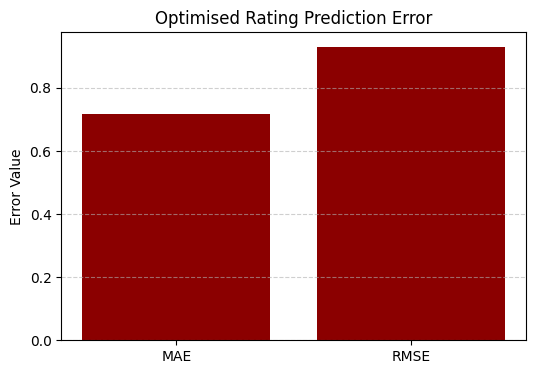

In [26]:
import matplotlib.pyplot as plt

#values from your evaluation
metrics = ['MAE', 'RMSE']
values = [mae, rmse]

plt.figure (figsize=(6,4))
plt.bar(metrics, values, color='darkred')
plt. title("Optimised Rating Prediction Error")
plt.ylabel("Error Value")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()


####Ranking-Based Evaluation Metrics

In [27]:
K = 20
precision_list = []
recall_list = []


#accessing test ratings of each user separately by grouping
test_user_groups = test_df.groupby("userId")

for user_id, group in test_user_groups:

    #get top 10 movie recommendations for that user
    recs = generate_recommendation(model_knn, user_id, n=K)

    #skipping users with no recommendations
    if recs is None or len(recs) == 0:
        continue

    #converting recommended movies into a set
    recommended_items = list(recs['title'])
    recommended_set = set(recommended_items)

    #movies with rating >= 4 that are liked by the user
    liked_items = set(group[group.rating >= 4]['title'])

    #skipping if user didn't like any movies
    if len(liked_items) == 0:
        continue

    #appending the movies that are both recommended and liked
    num_liked_and_recommended = len(recommended_set & liked_items)
    precision = num_liked_and_recommended / K
    precision_list.append(precision)

    recall = num_liked_and_recommended / len(liked_items)
    recall_list.append(recall)

#average the metrics across all users
avg_precision = np.mean(precision_list)
avg_recall = np.mean(recall_list)

print(f"Precision@{K}: {avg_precision:.6f}")
print(f"Recall@{K}: {avg_recall:.6f}")

#BASELINE: k was considered 5
#BASELINE Precision@@5: 0.212654
#BASELINE Recall@5: 0.152467

User ID 138 not found in dataset.
Precision@20: 0.153874
Recall@20: 0.460134


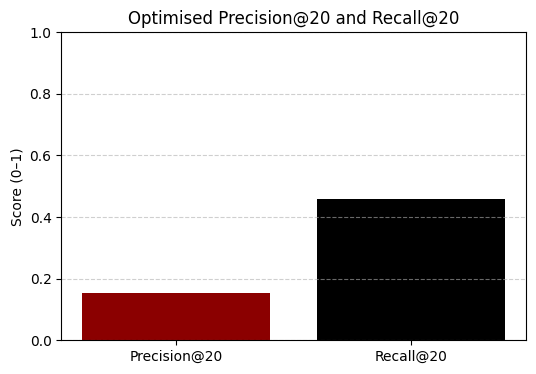

In [28]:
avg_precision = np.mean(precision_list)
avg_recall = np.mean(recall_list)

plt.figure(figsize=(6,4))
plt.bar(['Precision@'+str(K), 'Recall@'+str(K)],
        [avg_precision, avg_recall],
        color=['darkred', 'black'])

plt.title(f"Optimised Precision@{K} and Recall@{K}")
plt.ylim(0, 1)
plt.ylabel("Score (0–1)")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()
